In [ ]:

import numpy as np
import pandas as pd

from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines import AalenJohansenFitter  # for cumulative incidence (competing risks) :contentReference[oaicite:1]{index=1}

from sksurv.util import Surv  
from sksurv.ensemble import RandomSurvivalForest 
from sksurv.metrics import concordance_index_censored

In [17]:
import os
import re
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# Paths:
DATA_DIR = os.path.join('..', 'data')
OUT_DIR  = os.path.join('..', 'output')
os.makedirs(OUT_DIR, exist_ok=True)

NACC_MAIN_PATH = os.path.join(DATA_DIR, 'investigator_nacc72.csv')

USE_ONLY_V3 = False   # True => keep only FORMVER in {3, 3.2}

# Horizon sweep range
MIN_H = 3
MAX_H = 12

In [18]:
df = pd.read_csv(NACC_MAIN_PATH, low_memory=False)
df['NACCID'] = df['NACCID'].astype(str)

def make_visit_date(df_: pd.DataFrame) -> pd.Series:
    y = pd.to_numeric(df_['VISITYR'], errors='coerce')
    m = pd.to_numeric(df_['VISITMO'], errors='coerce').fillna(6).astype(int).clip(1, 12)
    d = pd.to_numeric(df_['VISITDAY'], errors='coerce').fillna(15).astype(int).clip(1, 28)
    return pd.to_datetime(dict(year=y, month=m, day=d), errors='coerce')

df['visit_date'] = make_visit_date(df)
df = df.dropna(subset=['NACCID', 'visit_date']).copy()
df = df.sort_values(['NACCID', 'visit_date']).reset_index(drop=True)

if 'FORMVER' in df.columns:
    df['FORMVER'] = pd.to_numeric(df['FORMVER'], errors='coerce')

print('Rows:', len(df), 'Participants:', df['NACCID'].nunique())
df[['NACCID','visit_date'] + ([ 'FORMVER' ] if 'FORMVER' in df.columns else [])].head()

Rows: 207454 Participants: 55268


,NACCID,visit_date,FORMVER
0,NACC000011,2006-04-17,1.0
1,NACC000011,2007-06-18,1.0
2,NACC000011,2008-06-03,2.0
3,NACC000011,2009-08-03,2.0
4,NACC000034,2015-07-16,3.0


In [ ]:


if "DEMENTED" in df.columns:
    no_dem_mask = df["DEMENTED"] == 0
else:
    no_dem_mask = pd.Series(True, index=df.index)

if "NACCUDSD" in df.columns:
    cnmci_mask = df["NACCUDSD"].isin([1,2,3])
else:
    cn_mask = (df["NORMCOG"] == 1) if "NORMCOG" in df.columns else pd.Series(False, index=df.index)
    mci_mask = df["NACCTMCI"].isin([1,2,3,4]) if "NACCTMCI" in df.columns else pd.Series(False, index=df.index)

    if ("NORMCOG" in df.columns) or ("NACCTMCI" in df.columns):
        cnmci_mask = cn_mask | mci_mask
    else:
        cnmci_mask = pd.Series(True, index=df.index)

eligible = df[no_dem_mask & cnmci_mask].copy()

baseline = (
    eligible
    .sort_values(["NACCID","visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

baseline = baseline[["NACCID","visit_date"]]
baseline = baseline.rename(columns={"visit_date":"baseline_date"})

print("Baseline participants:", len(baseline))
baseline.head()

/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_16674/240382410.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline participants: 38341


,NACCID,baseline_date
0,NACC000011,2006-04-17
1,NACC000034,2015-07-16
2,NACC000067,2012-05-23
3,NACC000073,2016-05-20
4,NACC000138,2023-07-13


In [24]:
def years_between(a: pd.Series, b: pd.Series) -> pd.Series:
    return (b - a).dt.days / 365.25

keep_ids = set(baseline['NACCID'])
df2 = df[df['NACCID'].isin(keep_ids)].merge(
    baseline[['NACCID','baseline_date']], on='NACCID', how='left'
).copy()

df2['t_years'] = years_between(df2['baseline_date'], df2['visit_date'])
post = df2[df2['t_years'] > 0].copy()

print("=== CHECKPOINT: post ===")
print("baseline N:", baseline["NACCID"].nunique())
print("post rows:", len(post), " post unique IDs:", post["NACCID"].nunique())
print("post visit_date min/max:", post["visit_date"].min(), post["visit_date"].max())
print("t_years min/max:", post["t_years"].min(), post["t_years"].max())

max_follow = post.groupby('NACCID')['t_years'].max().rename('max_follow_years')
baseline2 = baseline.merge(max_follow, on='NACCID', how='left')

print("\n=== CHECKPOINT: follow-up ===")
print("max_follow_years describe:")
display(baseline2["max_follow_years"].describe())
print("eligible @4y:", (baseline2["max_follow_years"] >= 4).sum())
print("eligible @5y:", (baseline2["max_follow_years"] >= 5).sum())

baseline2['max_follow_years'] = baseline2['max_follow_years'].fillna(0)

#DEMENTED: 0-No, 1-Yes
#NACCUDSD:1-Normal, 2-Impaired not MCI, 3-MCI, 4-Dementia
if 'NACCUDSD' in post.columns:
    dem_events_all = post[post['NACCUDSD'] == 4].copy()
    dementia_def = 'NACCUDSD==4'
else:
    dem_events_all = post[post['DEMENTED'] == 1].copy()
    dementia_def = 'DEMENTED==1'

first_dem_ever = (dem_events_all.sort_values(['NACCID','visit_date'])
                           .groupby('NACCID', as_index=False)
                           .first()
                           .rename(columns={'visit_date':'dementia_date'}))

first_dem_ever = first_dem_ever.merge(
    baseline2[['NACCID', 'baseline_date', 'max_follow_years']],
    on='NACCID',
    how='left',
    suffixes=('', '_base')   # prevent baseline_date_x/y
)

# Normalizing baseline_date if it got duplicated:
if 'baseline_date' not in first_dem_ever.columns:
    for c in ['baseline_date_base', 'baseline_date_x', 'baseline_date_y']:
        if c in first_dem_ever.columns:
            first_dem_ever['baseline_date'] = first_dem_ever[c]
            break
        
first_dem_ever['time_to_dem_years'] = years_between(first_dem_ever['baseline_date'], first_dem_ever['dementia_date'])

print("\n=== CHECKPOINT: first_dem_ever ===")
print("first_dem_ever unique IDs:", first_dem_ever["NACCID"].nunique())
print("time_to_dem_years min/median/max:",
      first_dem_ever["time_to_dem_years"].min(),
      first_dem_ever["time_to_dem_years"].median(),
      first_dem_ever["time_to_dem_years"].max())

print('Dementia event definition:', dementia_def)
print('Participants with ANY post-baseline dementia event:', first_dem_ever['NACCID'].nunique())
first_dem_ever[['NACCID','baseline_date','dementia_date','time_to_dem_years']].head()

=== CHECKPOINT: post ===
baseline N: 38341
post rows: 123654  post unique IDs: 27703
post visit_date min/max: 2006-04-03 00:00:00 2025-10-21 00:00:00
t_years min/max: 0.008213552361396304 19.392197125256672

=== CHECKPOINT: follow-up ===
max_follow_years describe:


count    27703.000000
mean         5.499126
std          4.268776
min          0.109514
25%          2.080767
50%          4.301164
75%          7.685147
max         19.392197
Name: max_follow_years, dtype: float64

eligible @4y: 14853
eligible @5y: 12474

=== CHECKPOINT: first_dem_ever ===
first_dem_ever unique IDs: 5502
time_to_dem_years min/median/max: 0.4188911704312115 2.6885694729637235 19.304585900068446
Dementia event definition: NACCUDSD==4
Participants with ANY post-baseline dementia event: 5502


/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_16674/2987371432.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


,NACCID,baseline_date,dementia_date,time_to_dem_years
0,NACC000034,2015-07-16,2021-05-21,5.848049
1,NACC000162,2009-03-10,2017-11-10,8.670773
2,NACC000225,2009-09-23,2017-07-07,7.786448
3,NACC000271,2007-06-20,2009-05-14,1.900068
4,NACC000333,2021-05-13,2024-07-24,3.197810


In [28]:
def subtype_primary(row):
    # Alzheimer's disease
    if "NACCALZD" in row and row["NACCALZD"] == 1:
        return "AD"

    # Lewy body disease
    if "NACCLBDE" in row and row["NACCLBDE"] == 1:
        return "PD_LBD"

    # Vascular brain injury
    if "CVD" in row and row["CVD"] == 1:
        return "Vascular"

    return "Other/Unk"


def subtype_anymention(row):
    if ("NACCALZD" in row and row["NACCALZD"] == 1):
        return "AD"

    if ("NACCLBDE" in row and row["NACCLBDE"] == 1):
        return "PD_LBD"

    if ("CVD" in row and row["CVD"] == 1):
        return "Vascular"

    return "Other/Unk"


def subtype_contributing(row):
    if "NACCALZP" in row and row["NACCALZP"] in [1,2]:
        return "AD"

    if "NACCLBDP" in row and row["NACCLBDP"] in [1,2]:
        return "PD_LBD"

    if "CVDIF" in row and row["CVDIF"] in [1,2]:
        return "Vascular"

    return "Other/Unk"

In [29]:
first_dem_ever["subtype_primary"] = first_dem_ever.apply(subtype_primary, axis=1)
first_dem_ever["subtype_any"]     = first_dem_ever.apply(subtype_anymention, axis=1)
first_dem_ever["subtype_contrib"] = first_dem_ever.apply(subtype_contributing, axis=1)

first_dem_ever["subtype_primary_contrib"] = np.where(
    first_dem_ever["subtype_primary"].eq("Other/Unk"),
    first_dem_ever["subtype_contrib"],
    first_dem_ever["subtype_primary"],
)

first_dem_ever["subtype_primary_contrib_any"] = np.where(
    first_dem_ever["subtype_primary_contrib"].eq("Other/Unk"),
    first_dem_ever["subtype_any"],
    first_dem_ever["subtype_primary_contrib"],
)

In [ ]:

# Building survival dataset

surv = baseline2[["NACCID", "baseline_date", "max_follow_years"]].copy()

surv = surv.merge(
    first_dem_ever[[
        "NACCID",
        "dementia_date",
        "time_to_dem_years",
        "subtype_primary_contrib_any"
    ]],
    on="NACCID",
    how="left"
)

# Event indicator
surv["event_observed"] = surv["dementia_date"].notna().astype(int)

# Time-to-event
surv["time_to_event"] = np.where(
    surv["event_observed"] == 1,
    surv["time_to_dem_years"],
    surv["max_follow_years"]
)

# Event subtype
surv["event_type"] = np.where(
    surv["event_observed"] == 1,
    surv["subtype_primary_contrib_any"],
    "Censored"
)

print("Survival dataset size:", len(surv))
print(surv["event_type"].value_counts(dropna=False))
surv.head()

Survival dataset size: 38341
event_type
Censored     32839
AD            4481
Other/Unk      609
PD_LBD         326
Vascular        86
Name: count, dtype: int64


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored
3,NACC000073,2016-05-20,0.000000,NaT,NaN,NaN,0,0.000000,Censored
4,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored


In [31]:
surv = surv[surv["time_to_event"] > 0].copy()

In [32]:
surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()
print(surv_main["event_type"].value_counts())

event_type
Censored    22201
AD           4481
PD_LBD        326
Vascular       86
Name: count, dtype: int64


In [33]:
surv["event_any_dementia"] = (surv["event_observed"] == 1).astype(int)

In [ ]:
# Removing zero follow-up rows
surv = surv[surv["time_to_event"] > 0].copy()


surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()

# Any-dementia event
surv_main["event_any_dementia"] = (surv_main["event_type"] != "Censored").astype(int)

print("After cleanup:", len(surv_main))
print(surv_main["event_type"].value_counts(dropna=False))
print(surv_main["event_any_dementia"].value_counts(dropna=False))

After cleanup: 27094
event_type
Censored    22201
AD           4481
PD_LBD        326
Vascular       86
Name: count, dtype: int64
event_any_dementia
0    22201
1     4893
Name: count, dtype: int64


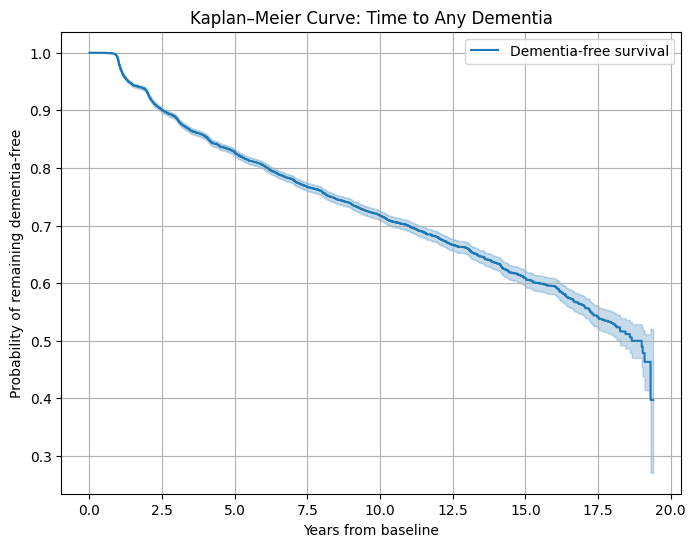

In [35]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations=surv_main["time_to_event"],
    event_observed=surv_main["event_any_dementia"],
    label="Dementia-free survival"
)

plt.figure(figsize=(8,6))
kmf.plot_survival_function()
plt.title("Kaplan–Meier Curve: Time to Any Dementia")
plt.xlabel("Years from baseline")
plt.ylabel("Probability of remaining dementia-free")
plt.grid(True)
plt.show()

In [ ]:
cox_features = [
    "NACCAGE",     
    "SEX",
    "EDUC",
    "NACCMMSE",     
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "APNEA"
]

In [ ]:

baseline_full = (
    df[df["NACCID"].isin(baseline["NACCID"])]
    .sort_values(["NACCID", "visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

print("Baseline rows with predictors:", len(baseline_full))
baseline_full.head()

/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_16674/1429174145.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline rows with predictors: 38341


,NACCID,NACCADC,PACKET,FORMVER,VISITMO,VISITDAY,VISITYR,NACCVNUM,NACCAVST,NACCNVST,NACCDAYS,NACCFDYS,NACCCORE,NACCREAS,NACCREFR,BIRTHMO,BIRTHYR,SEX,HISPANIC,HISPOR,HISPORX,RACE,RACEX,RACESEC,RACESECX,RACETER,RACETERX,PRIMLANG,PRIMLANX,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,HANDED,INBIRMO,INBIRYR,INSEX,NEWINF,INHISP,INHISPOR,INHISPOX,NACCNINR,INRACE,INRACEX,INRASEC,INRASECX,INRATER,INRATERX,INEDUC,INRELTO,INRELTOX,INKNOWN,INLIVWTH,INVISITS,INCALLS,INRELY,NACCFAM,NACCMOM,NACCDAD,NACCAM,NACCAMX,NACCAMS,NACCAMSX,NACCFM,NACCFMX,NACCFMS,NACCFMSX,NACCOM,NACCOMX,NACCOMS,NACCOMSX,NACCFADM,NACCFFTD,ANYMEDS,DRUG1,DRUG2,DRUG3,DRUG4,DRUG5,DRUG6,DRUG7,DRUG8,DRUG9,DRUG10,DRUG11,DRUG12,DRUG13,DRUG14,DRUG15,DRUG16,DRUG17,DRUG18,DRUG19,DRUG20,DRUG21,DRUG22,DRUG23,DRUG24,DRUG25,...,NPFTD,NPFTDTDP,NPALSMND,NPOFTD,NPOFTD1,NPOFTD2,NPOFTD3,NPOFTD4,NPOFTD5,NPFTDNO,NPFTDSPC,NPTDPA,NPTDPB,NPTDPC,NPTDPD,NPTDPE,NPPDXA,NPPDXB,NACCPRIO,NPPDXD,NPPDXE,NPPDXF,NPPDXG,NPPDXH,NPPDXI,NPPDXJ,NPPDXK,NPPDXL,NPPDXM,NPPDXN,NACCDOWN,NPPDXP,NPPDXQ,NACCOTHP,NACCWRI1,NACCWRI2,NACCWRI3,NACCBNKF,NPBNKB,NACCFORM,NACCPARA,NACCCSFP,NPBNKF,NPFAUT,NPFAUT1,NPFAUT2,NPFAUT3,NPFAUT4,NACCDAGE,NACCINT,NPNIT,NPCERAD,NPADRDA,NPOCRIT,NPVOTH,NPLEWYCS,NPGENE,NPFHSPEC,NPTAUHAP,NPPRNP,NPCHROM,NPPNORM,NPCNORM,NPPADP,NPCADP,NPPAD,NPCAD,NPPLEWY,NPCLEWY,NPPVASC,NPCVASC,NPPFTLD,NPCFTLD,NPPHIPP,NPCHIPP,NPPPRION,NPCPRION,NPPOTH1,NPCOTH1,NPOTH1X,NPPOTH2,NPCOTH2,NPOTH2X,NPPOTH3,NPCOTH3,NPOTH3X,NPARTAG,NPATGSEV,NPATGAMY,NPATGAM1,NPATGAM2,NPATGAM3,NPATGAM4,NPATGAM5,NPATGFRN,NPATGFR1,NPATGFR2,NPATGFR3,NPATGFR4,visit_date
0,NACC000011,1416,I,1.0,4,17,2006,1,4,4,1204,0,1,1,8,2,1944,2,0,88,None,1,None,88,None,88,None,1,None,16,1,2,1,1,2,10,1930,1,-4,0,88,None,1,1,None,88,None,88,None,12,5,None,-4,0,2,1,0,9,9,9,-4,None,-4,None,-4,None,-4,None,-4,None,-4,None,0,0,1,CONJUGATED ESTROGENS,CALCIUM-VITAMIN D,CALCIUM-VITAMIN D,MULTIVITAMIN,GLUCOSAMINE,UBIQUINONE,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,-4,-4,-4,-4,None,None,None,None,888,888,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,None,-4.0,-4.0,None,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,2006-04-17
1,NACC000034,9661,I,3.0,7,16,2015,1,7,6,2552,0,1,1,1,8,1935,2,0,88,None,1,None,88,None,88,None,1,None,15,2,1,1,1,2,1,1960,2,-4,0,88,None,1,1,None,88,None,88,None,12,2,None,55,0,5,3,0,1,1,1,0,None,-4,None,0,None,-4,None,0,None,-4,None,0,0,1,ATENOLOL,ASPIRIN,LEVOTHYROXINE,OMEGA-3 POLYUNSATURATED FATTY ACIDS,LISINOPRIL,CHOLECALCIFEROL,CALCIUM-VITAMIN D,MULTIVITAMIN,FLAX,MULTIVITAMIN,MULTIVITAMIN WITH MINERALS,ZINC SULFATE,DONEPEZIL,FLAX,UBIQUINONE,BIFIDOBACTERIUM-LACTOBACILLUS,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,-4,-4,-4,-4,None,None,None,None,888,888,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,None,-4.0,-4.0,None,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,2015-07-16
2,NACC000067,2096,I,2.0,5,23,2012,1,3,3,763,0,1,1,2,4,1952,1,0,88,None,1,None,88,None,88,None,1,None,18,1,2,2,1,1,1,1948,2,-4,0,88,None,1,1,None,88,None,88,None,16,1,None,-4,1,8,8,0,1,1,0,-4,None,-4,None,-4,None,-4,None,-4,None,-4,None,0,0,1,LORAZEPAM,CHOLESTYRAMINE,DOXEPIN,CYANOCOBALAMIN,ZOLPIDEM,LOPERAMIDE,ACETAMINOPHEN-HYDROCODONE,CARBIDOPA-LEVODOPA,TIMOLOL OPHTHALMIC,BRIMONIDINE OPHTHALMIC,TESTOSTERONE TOPICAL,CITALOPRAM,BIMATOPROST OPHTHALMIC,BIMATOPROST OPHTHALMIC,MELATONIN,CITALOPRAM,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,

In [ ]:
baseline_features = baseline_full[["NACCID"] + [c for c in cox_features if c in baseline_full.columns]].copy()

# Merging into survival dataframe
cox_df = surv_main.merge(baseline_features, on="NACCID", how="left")

print("Rows after merge:", len(cox_df))
cox_df.head()

Rows after merge: 27094


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type,event_any_dementia,NACCAGE,SEX,EDUC,NACCMMSE,CDRSUM,DIABETES,HYPERTEN,HYPERCHO,CBSTROKE,CVAFIB,DEP2YRS,APNEA
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored,0,62,2,16,30,0.5,0,0,0,0,0,0,-4
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD,1,79,2,15,-4,0.5,0,1,0,0,0,0,0
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored,0,60,1,18,29,0.5,0,0,0,0,0,1,-4
3,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored,0,54,2,16,-4,0.0,0,0,0,0,0,0,0
4,NACC000144,2010-08-17,8.487337,NaT,NaN,NaN,0,8.487337,Censored,0,79,1,18,30,0.0,0,1,1,0,1,1,-4


In [40]:
cox_df["event_any_dementia"] = (cox_df["event_type"] != "Censored").astype(int)

In [41]:
model_cols = ["time_to_event", "event_any_dementia"] + [c for c in cox_features if c in cox_df.columns]
cox_df_model = cox_df[model_cols].copy()

print(cox_df_model.columns.tolist())

['time_to_event', 'event_any_dementia', 'NACCAGE', 'SEX', 'EDUC', 'NACCMMSE', 'CDRSUM', 'DIABETES', 'HYPERTEN', 'HYPERCHO', 'CBSTROKE', 'CVAFIB', 'DEP2YRS', 'APNEA']


In [42]:
for col in cox_df_model.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    if cox_df_model[col].dtype.kind in "biufc":
        cox_df_model[col] = cox_df_model[col].fillna(cox_df_model[col].median())
    else:
        mode_vals = cox_df_model[col].mode()
        if len(mode_vals) > 0:
            cox_df_model[col] = cox_df_model[col].fillna(mode_vals.iloc[0])

In [43]:
cox_df_model = cox_df_model[
    cox_df_model["time_to_event"].notna() &
    (cox_df_model["time_to_event"] > 0)
].copy()

print("Final Cox rows:", len(cox_df_model))

Final Cox rows: 27094


In [44]:
from lifelines import CoxPHFitter

cox = CoxPHFitter(penalizer=0.1)
cox.fit(
    cox_df_model,
    duration_col="time_to_event",
    event_col="event_any_dementia"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 27094 total observations, 22201 right-censored observations>
             duration col = 'time_to_event'
                event col = 'event_any_dementia'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 27094
number of events observed = 4893
   partial log-likelihood = -43951.80
         time fit was run = 2026-03-06 22:42:51 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
NACCAGE    0.03      1.03      0.00            0.03            0.04                1.03                1.04
SEX       -0.17      0.85      0.02           -0.21           -0.12                0.81                0.88
EDUC      -0.00      1.00      0.00           -0.01            0.00                0.99                1.00
NACCMMSE  -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
CDRSUM     0.55      1.74      0.01            0.54            0.57                1.72                1.77
DIABETES  -0.04      0.96      0.02           -0.08           -0.01                0.92                0.99
HYPERTEN  -0.00      1.00      0.01           -0.03            0.03                0.97                1.03
HYPERCHO   0.01      1.01      0.01           -0.01            0.03                0.99                1.03
CBSTROKE   0.03      1.03      0.02           -0.01            0.06                0.99                1.06
CVAFIB     0.01      1.01      0.01           -0.02            0.04                0.98                1.04
DEP2YRS    0.06      1.06      0.01            0.04            0.08                1.04                1.09
APNEA     -0.02      0.98      0.01           -0.03           -0.00                0.97                1.00

           cmp to     z      p  -log2(p)
covariate                               
NACCAGE      0.00 26.93 <0.005    528.12
SEX          0.00 -7.22 <0.005     40.85
EDUC         0.00 -1.08   0.28      1.83
NACCMMSE     0.00 -3.47 <0.005     10.90
CDRSUM       0.00 74.84 <0.005       inf
DIABETES     0.00 -2.44   0.01      6.08
HYPERTEN     0.00 -0.18   0.86      0.23
HYPERCHO     0.00  0.73   0.46      1.11
CBSTROKE     0.00  1.52   0.13      2.97
CVAFIB       0.00  0.49   0.62      0.68
DEP2YRS      0.00  5.07 <0.005     21.27
APNEA        0.00 -2.65   0.01      6.98
---
Concordance = 0.85
Partial AIC = 87927.60
log-likelihood ratio test = 4399.23 on 12 df
-log2(p) of ll-ratio test = inf

In [45]:
hr_table = cox.summary[[
    "coef",
    "exp(coef)",
    "se(coef)",
    "p"
]].copy()

hr_table = hr_table.rename(columns={
    "coef": "log_hazard",
    "exp(coef)": "hazard_ratio",
    "se(coef)": "se",
    "p": "p_value"
})

hr_table.sort_values("p_value").head(20)

,log_hazard,hazard_ratio,se,p_value
covariate,,,,
CDRSUM,0.554853,1.741684,0.007414,0.000000e+00
NACCAGE,0.033515,1.034083,0.001245,1.047838e-159
SEX,-0.168039,0.845321,0.023261,5.050540e-13
DEP2YRS,0.059820,1.061645,0.011796,3.952544e-07
NACCMMSE,-0.002563,0.997441,0.000739,5.231095e-04
APNEA,-0.015181,0.984934,0.005718,7.935185e-03
DIABETES,-0.044647,0.956335,0.018321,1.480994e-02
CBSTROKE,0.027426,1.027805,0.018014,1.278872e-01
EDUC,-0.002151,0.997852,0.001993,2.805214e-01


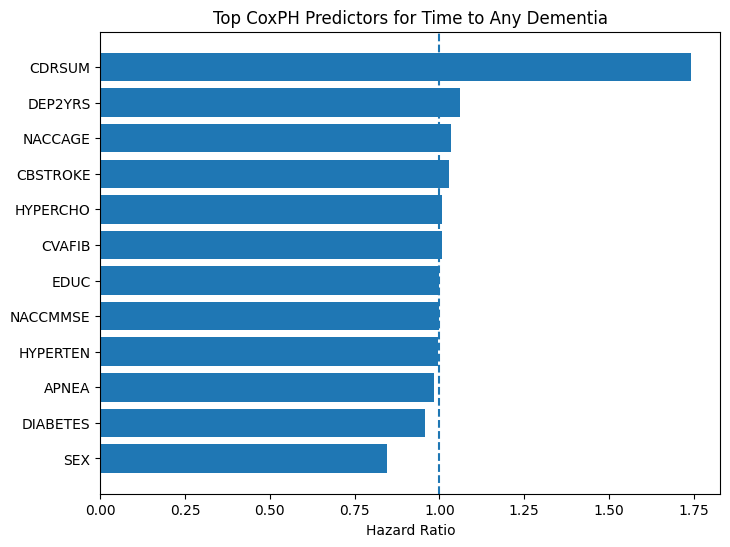

In [46]:
import matplotlib.pyplot as plt

top_hr = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

plt.figure(figsize=(8,6))
plt.barh(top_hr.index.astype(str), top_hr["hazard_ratio"])
plt.axvline(1.0, linestyle="--")
plt.xlabel("Hazard Ratio")
plt.title("Top CoxPH Predictors for Time to Any Dementia")
plt.show()

In [47]:
cox.check_assumptions(cox_df_model, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'NACCAGE' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'NACCAGE' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'NACCAGE' using pd.cut, and then specify it in
`strata=['NACCAGE', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'SEX' failed the non-proportional test: p-value is 0.0173.

   Advice: with so few unique values (only 2), you can include `strata=['SEX', ...]` in the call in
`.fit`. See documentation in link [E] below.

3. Variable 'CDRSUM' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'CDRSUM' might b

[]